# Transaction Dynamics
### Purpose : Analyze transaction dynamics across states and categories

C:\Users\Vijay\AppData\Local\Temp\ipykernel_7160\1672710347.py:19: UserWarning:

pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.



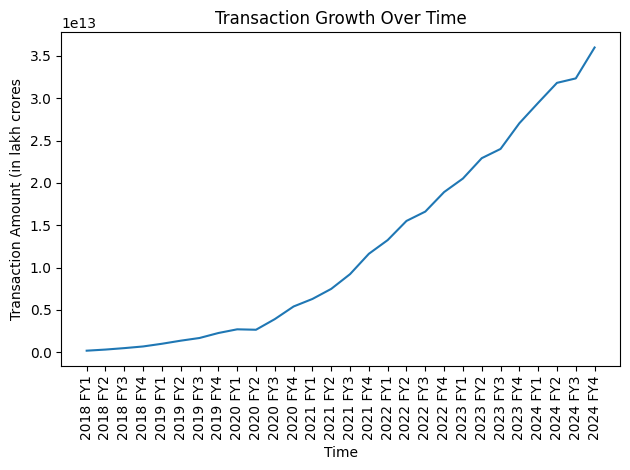

In [ ]:
import pandas as pd
import plotly.express as px
import mysql.connector

conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password="12345678",
    database="phonepe_db"
)

# Your exact query
query = """
WITH combined_category AS (
    SELECT 
        State,
        SUM(Transaction_amount) AS Total_Amount
    FROM aggregated_transaction
    WHERE Category_Name IN ('Merchant Payments', 'Financial Services')
    GROUP BY State
),

state_rank AS (
    SELECT 
        State,
        Total_Amount,
        RANK() OVER (ORDER BY Total_Amount DESC) AS State_Rank
    FROM combined_category
)

SELECT 
    State,
    Total_Amount,
    State_Rank
FROM state_rank
ORDER BY State_Rank;
"""

# Load data
df = pd.read_sql(query, engine)

# Visualization (no extra processing)
fig = px.bar(
    df,
    x="Total_Amount",
    y="State",
    orientation="h",
    text="State_Rank",
    title="Transaction Dynamics: State Ranking (Merchant + Financial)"
)

fig.update_traces(textposition='outside')

fig.update_layout(
    xaxis_title="Total Transaction Amount",
    yaxis_title="State"
)

fig.show()

#  State-wise Transaction Analysis

C:\Users\Vijay\AppData\Local\Temp\ipykernel_7160\2322464639.py:23: UserWarning:

pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.



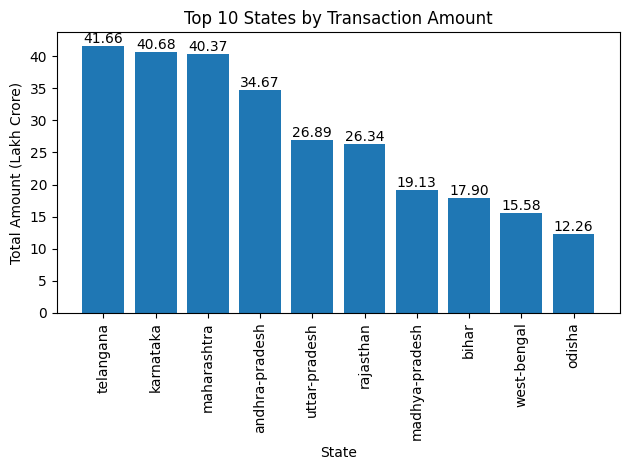

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import mysql.connector

connection = mysql.connector.connect(
    host="localhost",
    user="root",
    password="12345678",
    database="phonepe_db"
)

query = """
SELECT 
    State,
    SUM(Transaction_amount) AS Total_Amount,
    ROUND(SUM(Transaction_amount)/1000000000000, 2) AS Total_Amount_LakhCrore
FROM aggregated_transaction
GROUP BY State
ORDER BY Total_Amount DESC
LIMIT 10;
"""

df = pd.read_sql(query, connection)

plt.figure()

bars = plt.bar(df["State"], df["Total_Amount_LakhCrore"])

# Add value labels on top of bars
for bar in bars:
    y = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        y,
        f"{y:.2f}",  
        ha='center',
        va='bottom'
    )

plt.xticks(rotation=90)
plt.title("Top 10 States by Transaction Amount")
plt.xlabel("State")
plt.ylabel("Total Amount (Lakh Crore)")
plt.tight_layout()

plt.show()